## KNN Baseline Result

KNN was tuned using the validation subset of the official Fashion-MNIST
training data.

The selected configuration used:

- PCA components: **[N]**
- Number of neighbours: **[BEST_K]**
- Test accuracy: **[ACCURACY]**
- Test macro-F1: **[F1]**
- Fit time: **[FIT] seconds**
- Prediction time: **[PREDICT] seconds**

The official test set was used only after selecting the KNN hyperparameter
using validation performance.

This result serves as the baseline for comparison with SVM, Random Forest,
and MLP.

In [4]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data import load_idx_images, load_idx_labels
from src.preprocessing import prepare_features, create_validation_split

In [5]:
DATA_DIR = PROJECT_ROOT / "data" / "raw"

X_train_raw = load_idx_images(
    DATA_DIR / "train-images-idx3-ubyte.gz"
)

y_train_full = load_idx_labels(
    DATA_DIR / "train-labels-idx1-ubyte.gz"
)

X_test_raw = load_idx_images(
    DATA_DIR / "t10k-images-idx3-ubyte.gz"
)

y_test = load_idx_labels(
    DATA_DIR / "t10k-labels-idx1-ubyte.gz"
)

print("Training images:", X_train_raw.shape)
print("Training labels:", y_train_full.shape)
print("Test images:", X_test_raw.shape)
print("Test labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


In [6]:
X_full = prepare_features(X_train_raw)
X_test = prepare_features(X_test_raw)

print("Training features:", X_full.shape)
print("Test features:", X_test.shape)
print("Feature range:", X_full.min(), X_full.max())

Training features: (60000, 784)
Test features: (10000, 784)
Feature range: 0.0 1.0


In [7]:
X_train, X_val, y_train, y_val = create_validation_split(
    X_full,
    y_train_full,
    validation_size=0.2,
    random_state=42,
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (48000, 784) (48000,)
Validation: (12000, 784) (12000,)
Test: (10000, 784) (10000,)


In [8]:
N_COMPONENTS =187
pca = PCA(
    n_components=N_COMPONENTS,
    random_state=42,
)

X_train_pca = pca.fit_transform(X_train)

X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

print("Training PCA:", X_train_pca.shape)
print("Validation PCA:", X_val_pca.shape)
print("Test PCA:", X_test_pca.shape)

print(
    "Retained variance:",
    pca.explained_variance_ratio_.sum(),
)

Training PCA: (48000, 187)
Validation PCA: (12000, 187)
Test PCA: (10000, 187)
Retained variance: 0.9500228


## KNN Hyperparameter Selection

KNN is evaluated using several values of `k`.

The value of `k` is selected using validation accuracy. The official test set
is not used during hyperparameter selection.

The candidate values are:

- k = 3
- k = 5
- k = 7
- k = 9

After selecting the best value using the validation set, the chosen KNN model
is evaluated on the official Fashion-MNIST test set.

In [9]:
K_VALUES = [3, 5, 7, 9]

knn_results = []

for k in K_VALUES:

    model = KNeighborsClassifier(
        n_neighbors=k,
        n_jobs=-1,
    )

    fit_start = time.perf_counter()

    model.fit(
        X_train_pca,
        y_train,
    )

    fit_time = time.perf_counter() - fit_start

    predict_start = time.perf_counter()

    val_predictions = model.predict(
        X_val_pca
    )

    predict_time = time.perf_counter() - predict_start

    accuracy = accuracy_score(
        y_val,
        val_predictions,
    )

    macro_f1 = f1_score(
        y_val,
        val_predictions,
        average="macro",
    )

    knn_results.append(
        {
            "k": k,
            "accuracy": accuracy,
            "macro_f1": macro_f1,
            "fit_seconds": fit_time,
            "predict_seconds": predict_time,
        }
    )

    print(
        f"k={k} | "
        f"accuracy={accuracy:.4f} | "
        f"macro-F1={macro_f1:.4f} | "
        f"fit={fit_time:.3f}s | "
        f"predict={predict_time:.3f}s"
    )

k=3 | accuracy=0.8630 | macro-F1=0.8631 | fit=0.012s | predict=7.010s
k=5 | accuracy=0.8662 | macro-F1=0.8658 | fit=0.009s | predict=4.323s
k=7 | accuracy=0.8639 | macro-F1=0.8636 | fit=0.014s | predict=4.057s
k=9 | accuracy=0.8645 | macro-F1=0.8642 | fit=0.018s | predict=3.876s


In [10]:
for result in knn_results:
    print(result)


{'k': 3, 'accuracy': 0.863, 'macro_f1': 0.863078990589295, 'fit_seconds': 0.011769399978220463, 'predict_seconds': 7.0104255001060665}
{'k': 5, 'accuracy': 0.8661666666666666, 'macro_f1': 0.8658408804818232, 'fit_seconds': 0.009424800053238869, 'predict_seconds': 4.322975300252438}
{'k': 7, 'accuracy': 0.8639166666666667, 'macro_f1': 0.8636125501545576, 'fit_seconds': 0.014317900408059359, 'predict_seconds': 4.056642500218004}
{'k': 9, 'accuracy': 0.8645, 'macro_f1': 0.8642364015775081, 'fit_seconds': 0.017609499860554934, 'predict_seconds': 3.875783000141382}


In [11]:
best_result = max(
    knn_results,
    key=lambda result: result["accuracy"],
)

BEST_K = best_result["k"]

print("Best k:", BEST_K)
print(
    "Best validation accuracy:",
    best_result["accuracy"],
)

print(
    "Best validation macro-F1:",
    best_result["macro_f1"],
)

Best k: 5
Best validation accuracy: 0.8661666666666666
Best validation macro-F1: 0.8658408804818232


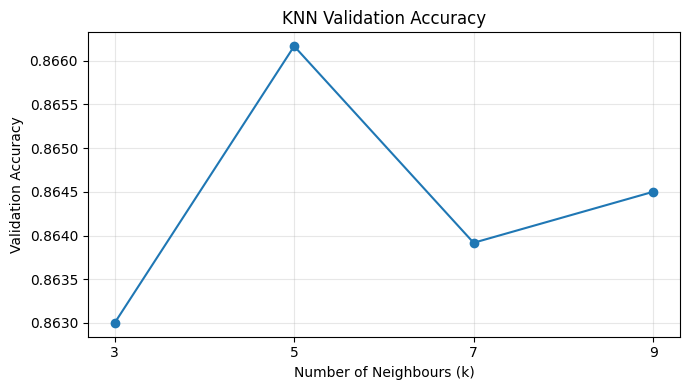

In [12]:
k_values = [
    result["k"]
    for result in knn_results
]

accuracies = [
    result["accuracy"]
    for result in knn_results
]

plt.figure(figsize=(7, 4))

plt.plot(
    k_values,
    accuracies,
    marker="o",
)

plt.xlabel("Number of Neighbours (k)")
plt.ylabel("Validation Accuracy")
plt.title("KNN Validation Accuracy")

plt.xticks(K_VALUES)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
best_knn = KNeighborsClassifier(
    n_neighbors=BEST_K,
    n_jobs=-1,
)
fit_start = time.perf_counter()

best_knn.fit(
    X_train_pca,
    y_train,
)

knn_fit_time = (
    time.perf_counter() - fit_start
)


In [14]:
predict_start = time.perf_counter()

y_test_pred = best_knn.predict(
    X_test_pca
)

knn_predict_time = (
    time.perf_counter() - predict_start
)
knn_test_accuracy = accuracy_score(
    y_test,
    y_test_pred,
)

knn_test_macro_f1 = f1_score(
    y_test,
    y_test_pred,
    average="macro",
)
print("KNN BASELINE")
print("---------------------------")
print("PCA components:", N_COMPONENTS)
print("Best k:", BEST_K)

print(
    "Test accuracy:",
    round(knn_test_accuracy, 4),
)

print(
    "Test macro-F1:",
    round(knn_test_macro_f1, 4),
)

print(
    "Fit time:",
    round(knn_fit_time, 3),
    "seconds",
)

print(
    "Predict time:",
    round(knn_predict_time, 3),
    "seconds",
)

KNN BASELINE
---------------------------
PCA components: 187
Best k: 5
Test accuracy: 0.8579
Test macro-F1: 0.8574
Fit time: 0.012 seconds
Predict time: 3.706 seconds


# Model Comparison — KNN Baseline

This notebook evaluates classical machine-learning classifiers on the PCA
representation of Fashion-MNIST.

The first model is K-Nearest Neighbours (KNN), which serves as the baseline
classifier for Checkpoint 1.

Hyperparameters are selected using the validation set. The official
Fashion-MNIST test set is not used for hyperparameter selection.

# RBF Support Vector Machine

The second classifier evaluated is a Support Vector Machine using the
Radial Basis Function (RBF) kernel.

The SVM uses the same preprocessing, training/validation split, and PCA
representation as the KNN baseline.

The hyperparameters `C` and `gamma` are selected using validation performance.
The official Fashion-MNIST test set is not used during hyperparameter selection.


In [ ]:
from sklearn.svm import SVC
import time
from sklearn.metrics import accuracy_score, f1_score

In [ ]:
from sklearn.model_selection import train_test_split

X_svm_search, _, y_svm_search, _ = train_test_split(
    X_train_pca,
    y_train,
    train_size=12000,
    random_state=42,
    stratify=y_train,
)

print("SVM tuning subset:", X_svm_search.shape)
print("SVM tuning labels:", y_svm_search.shape)

In [ ]:
C_VALUES = [1, 10]
GAMMA_VALUES = ["scale", 0.01]

svm_results = []

In [ ]:
for C in C_VALUES:
    for gamma in GAMMA_VALUES:

        model = SVC(
            kernel="rbf",
            C=C,
            gamma=gamma,
        )

        fit_start = time.perf_counter()

        model.fit(
            X_svm_search,
            y_svm_search,
        )

        fit_time = time.perf_counter() - fit_start

        predict_start = time.perf_counter()

        val_predictions = model.predict(
            X_val_pca
        )

        predict_time = time.perf_counter() - predict_start

        accuracy = accuracy_score(
            y_val,
            val_predictions,
        )

        macro_f1 = f1_score(
            y_val,
            val_predictions,
            average="macro",
        )

        svm_results.append(
            {
                "C": C,
                "gamma": gamma,
                "accuracy": accuracy,
                "macro_f1": macro_f1,
                "fit_seconds": fit_time,
                "predict_seconds": predict_time,
            }
        )

        print(
            f"C={C}, gamma={gamma} | "
            f"accuracy={accuracy:.4f} | "
            f"macro-F1={macro_f1:.4f} | "
            f"fit={fit_time:.2f}s | "
            f"predict={predict_time:.2f}s"
        )

In [ ]:
best_svm_result = max(
    svm_results,
    key=lambda result: result["accuracy"],
)

BEST_C = best_svm_result["C"]
BEST_GAMMA = best_svm_result["gamma"]

print("Best C:", BEST_C)
print("Best gamma:", BEST_GAMMA)
print(
    "Best validation accuracy:",
    best_svm_result["accuracy"],
)
print(
    "Best validation macro-F1:",
    best_svm_result["macro_f1"],
)

## SVM Hyperparameter Selection

RBF SVM hyperparameter tuning was performed on a reproducible stratified
subset of 12,000 examples from the model-training set.

A subset was used because RBF SVM training becomes computationally expensive
as the number of training examples increases.

The validation set remained unchanged and was used to compare candidate
configurations.

The search considered:

- `C`: 1 and 10
- `gamma`: `scale` and 0.01

The official test set was not used during hyperparameter selection.

In [ ]:
best_svm = SVC(
    kernel="rbf",
    C=BEST_C,
    gamma=BEST_GAMMA,
)

svm_fit_start = time.perf_counter()

best_svm.fit(
    X_train_pca,
    y_train,
)

svm_fit_time = (
    time.perf_counter() - svm_fit_start
)

print(
    "Final SVM fit time:",
    round(svm_fit_time, 3),
    "seconds",
)

In [ ]:
svm_predict_start = time.perf_counter()

y_test_pred_svm = best_svm.predict(
    X_test_pca
)

svm_predict_time = (
    time.perf_counter() - svm_predict_start
)

svm_test_accuracy = accuracy_score(
    y_test,
    y_test_pred_svm,
)

svm_test_macro_f1 = f1_score(
    y_test,
    y_test_pred_svm,
    average="macro",
)
print("RBF SVM RESULT")
print("---------------------------")
print("PCA components:", N_COMPONENTS)
print("C:", BEST_C)
print("Gamma:", BEST_GAMMA)

print(
    "Test accuracy:",
    round(svm_test_accuracy, 4),
)

print(
    "Test macro-F1:",
    round(svm_test_macro_f1, 4),
)

print(
    "Fit time:",
    round(svm_fit_time, 3),
    "seconds",
)

print(
    "Predict time:",
    round(svm_predict_time, 3),
    "seconds",
)

## RBF SVM Result

The RBF SVM hyperparameters were selected using validation performance after
a small search on a stratified subset of the model-training data.

Selected configuration:

- PCA components: **[N]**
- C: **[BEST_C]**
- Gamma: **[BEST_GAMMA]**
- Test accuracy: **[ACCURACY]**
- Test macro-F1: **[F1]**
- Fit time: **[FIT] seconds**
- Prediction time: **[PREDICT] seconds**

The selected configuration was trained using the complete model-training
subset before being evaluated on the official Fashion-MNIST test set.